# Handling Null values and standarization
Second part

In [324]:
import pandas as pd

datos = pd.read_csv('../data/bronze/staging/stg1_casas_gam_full2.csv')
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 546 entries, 0 to 545
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Total_area_m2     546 non-null    int64  
 1   Built_area_m2     546 non-null    int64  
 2   Rooms             546 non-null    int64  
 3   Bathrooms         546 non-null    int64  
 4   HalfBathrooms     546 non-null    int64  
 5   Parkings          546 non-null    int64  
 6   Antiguedad        504 non-null    float64
 7   Colonia           546 non-null    str    
 8   Price             546 non-null    int64  
 9   Maintenance_cost  546 non-null    int64  
 10  Address           543 non-null    str    
 11  PropertyType      546 non-null    str    
 12  IsAuction         546 non-null    bool   
 13  FlagsFeatures     56 non-null     str    
 14  HaveVideo         546 non-null    bool   
 15  Latitude          546 non-null    float64
 16  Longitude         546 non-null    float64
dtypes: bool(

### Elimination of unuseful variables

In [325]:
datos.drop(columns=['FlagsFeatures','IsAuction', 'Address'], inplace=True)

### Elimination of Outliners

#### Total_area_m2

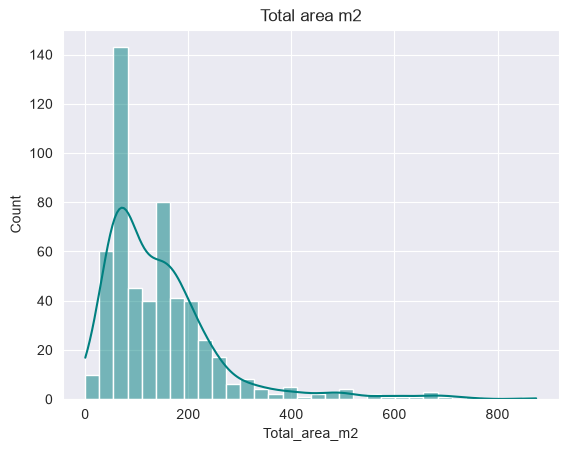

In [326]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('darkgrid')
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True)
plt.title('Total area m2')
plt.show()

In [327]:
datos['Total_area_m2'].describe()

count    546.000000
mean     146.349817
std      117.240818
min        0.000000
25%       65.000000
50%      124.000000
75%      180.000000
max      875.000000
Name: Total_area_m2, dtype: float64

Based on the data, Its very clear that there are some outliners which have a extremely elevated **Total_area_m2**. In order to change them, we're going to visualize how many of them have gotten high values and eliminate them if necesary.

In [328]:
datos['cuartiles_total_area_m2'] = pd.qcut(datos['Total_area_m2'], q=8, labels=['q1','q2','q3','q4','q5','q6','q7','q8'])
print(datos['cuartiles_total_area_m2'].value_counts().sort_index())
q8 = datos[(datos['cuartiles_total_area_m2'] == 'q8')]
q8['Total_area_m2'].describe()

cuartiles_total_area_m2
q1    70
q2    77
q3    58
q4    70
q5    67
q6    70
q7    68
q8    66
Name: count, dtype: int64


count     66.000000
mean     388.090909
std      150.762751
min      242.000000
25%      266.250000
50%      327.000000
75%      485.000000
max      875.000000
Name: Total_area_m2, dtype: float64

In [329]:
# 1. Calcular el valor del percentil 95
limite_superior = datos['Total_area_m2'].quantile(0.97)

num = len(datos)
# 2. Filtrar el DataFrame para conservar solo lo que está por debajo o igual a ese límite
datoslol = datos[datos['Total_area_m2'] <= limite_superior]

# (Opcional) Verificar cuántas filas se eliminaron
print(f"Filas originales: {num}")
print(f"Filas actuales: {len(datos)}")



Filas originales: 546
Filas actuales: 546


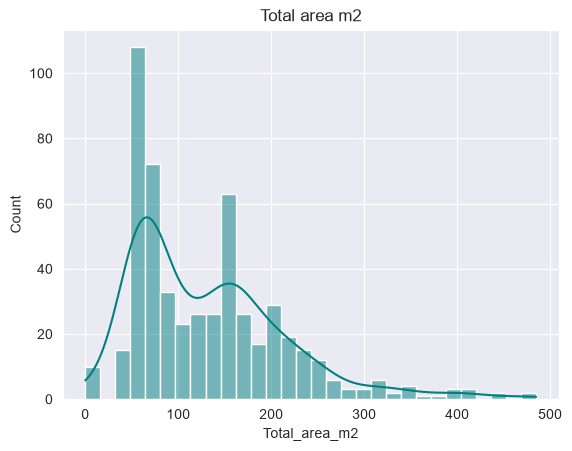

In [330]:
sns.histplot(data=datoslol,x='Total_area_m2', color='teal', kde=True, bins=30)
plt.title('Total area m2')
plt.show()

As we can see, the graphic has still outliners now on the left side, there shouldn't be registers with 0 m2 because that's physically impossible, its probable that there must have bn an error, With the intention to fix it, we'll see if the houses with 0 m2 on **Total_area_m2** have any value on **Built_area_m2**, if they've goteen a value, we'll assign it to **Total_area_m2**

In [331]:
datos[datos['Total_area_m2'] < 10][['Total_area_m2','Built_area_m2']].head(100)

,Total_area_m2,Built_area_m2
85,1,54
245,0,0
357,0,58
397,1,65
398,0,64
468,0,50
471,0,58
491,0,75
512,0,300
532,0,117


In [332]:
datos.loc[datos['Total_area_m2'] < 10, 'Total_area_m2'] = datos['Built_area_m2']
print(datos[datos['Total_area_m2'] < 10][['Total_area_m2', 'Built_area_m2']].head())

# We delete the values where both areas are 0
datos = datos[~((datos['Total_area_m2'] == 0) & (datos['Built_area_m2'] == 0))]


print(f"Total registers on the DataFrame After the dropping: {len(datos)}")


     Total_area_m2  Built_area_m2
245              0              0
Total registers on the DataFrame After the dropping: 545


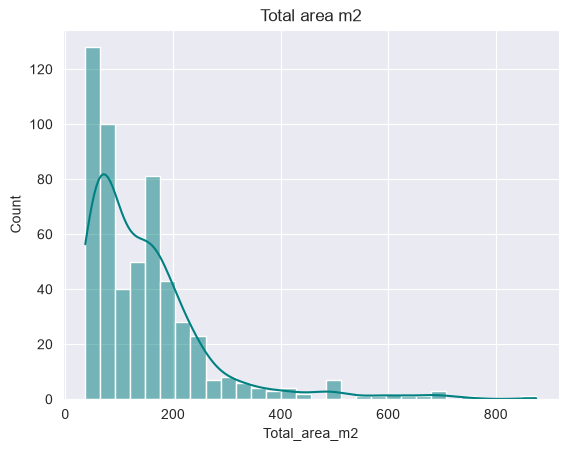

In [333]:
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True, bins=30)
plt.title('Total area m2')
plt.show()

C:\Users\ozzyr\AppData\Local\Temp\ipykernel_13956\791589688.py:1: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:steelblue'` for the same effect.

  sns.violinplot(data=datos,x='Total_area_m2', color='steelblue', hue='PropertyType')


<Axes: xlabel='Total_area_m2'>

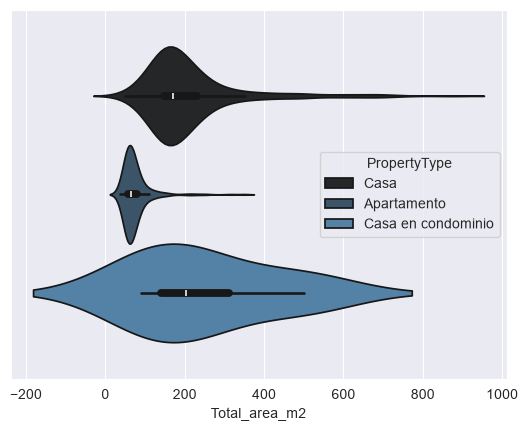

In [334]:
sns.violinplot(data=datos,x='Total_area_m2', color='steelblue', hue='PropertyType')

In [335]:
apartamentos = datos[datos['PropertyType'] == 'Apartamento']
apartamentos.describe()

,Total_area_m2,Built_area_m2,Rooms,Bathrooms,HalfBathrooms,Parkings,Antiguedad,Price,Maintenance_cost,Latitude,Longitude
count,254.000000,254.000000,254.000000,254.000000,254.000000,254.000000,240.000000,2.540000e+02,254.000000,254.000000,254.000000
mean,74.799213,74.657480,2.322835,1.472441,0.070866,0.905512,10.900000,1.318617e+07,324.118110,19.485367,-99.120183
std,38.475944,46.175606,0.851707,0.639006,0.257108,0.727039,14.948111,1.598094e+08,634.949721,0.019188,0.020795
min,37.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,6.850000e+05,0.000000,19.410130,-99.157270
25%,56.000000,55.250000,2.000000,1.000000,0.000000,0.000000,0.000000,2.141602e+06,0.000000,19.469487,-99.133163
50%,65.000000,65.000000,2.000000,1.000000,0.000000,1.000000,4.500000,2.775000e+06,0.000000,19.481149,-99.122153
75%,78.500000,77.750000,3.000000,2.000000,0.000000,1.000000,15.500000,3.809999e+06,330.000000,19.497735,-99.107964
max,349.000000,550.000000,9.000000,6.000000,1.000000,4.000000,70.000000,2.550000e+09,3402.000000,19.561398,-99.057233


In [336]:
# 1. Filtrar el DataFrame original para obtener solo los apartamentos
apartamentos = datos[datos['PropertyType'] == 'Apartamento'].copy()

# Guardar el número original de filas de apartamentos
num_apartamentos = len(apartamentos)

# 2. Calcular el valor del percentil 95 (o 99) para el área de los apartamentos
limite_superior_apto = apartamentos['Total_area_m2'].quantile(.99)

# 3. Filtrar el DataFrame de apartamentos para conservar solo lo que está por debajo o igual al límite
apartamentos = apartamentos[apartamentos['Total_area_m2'] <= limite_superior_apto]

# 4. Verificar cuántas filas se eliminaron
print(f"Apartamentos originales: {num_apartamentos}")
print(f"Apartamentos actuales (sin outliers): {len(apartamentos)}")

# 5. Mostrar la descripción estadística actualizada
apartamentos.describe()


Apartamentos originales: 254
Apartamentos actuales (sin outliers): 251


,Total_area_m2,Built_area_m2,Rooms,Bathrooms,HalfBathrooms,Parkings,Antiguedad,Price,Maintenance_cost,Latitude,Longitude
count,251.000000,251.000000,251.000000,251.000000,251.000000,251.000000,237.000000,2.510000e+02,251.000000,251.000000,251.000000
mean,72.027888,73.115538,2.294821,1.454183,0.071713,0.904382,10.489451,1.327971e+07,323.211155,19.485383,-99.120193
std,28.767816,40.895655,0.743460,0.573491,0.258528,0.725824,14.163277,1.607627e+08,635.680076,0.019300,0.020917
min,37.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,6.850000e+05,0.000000,19.410130,-99.157270
25%,55.500000,55.000000,2.000000,1.000000,0.000000,0.000000,0.000000,2.141300e+06,0.000000,19.469174,-99.133163
50%,65.000000,65.000000,2.000000,1.000000,0.000000,1.000000,4.000000,2.775000e+06,0.000000,19.481149,-99.122295
75%,77.000000,77.000000,3.000000,2.000000,0.000000,1.000000,15.000000,3.809999e+06,310.000000,19.497868,-99.107737
max,240.000000,550.000000,9.000000,4.000000,1.000000,4.000000,60.000000,2.550000e+09,3402.000000,19.561398,-99.057233


In [337]:
# --- PASO 1: Remover el percentil 95 de los datos en general ---
num_original = len(datos)
limite_general = datos['Total_area_m2'].quantile(.96)

# Filtrado global
datos_filtrados = datos[datos['Total_area_m2'] <= limite_general].copy()


# --- PASO 2: Calcular el percentil 99 de departamentos y remover sus outliers del dataset general ---
# 1. Identificar el límite del percentil 99 solo para los departamentos del set ya filtrado
limite_departamentos = datos_filtrados[datos_filtrados['PropertyType'] == 'Apartamento']['Total_area_m2'].quantile(0.99)

# 2. Excluir del dataset general aquellos registros que sean 'Apartamento' Y superen su límite específico
# (Mantenemos todo lo que NO sea apartamento, O los apartamentos que cumplan el límite)
filtro_deptos_outliers = (datos_filtrados['PropertyType'] == 'Apartamento') & (datos_filtrados['Total_area_m2'] > limite_departamentos)
datos = datos_filtrados[~filtro_deptos_outliers].copy()


# --- VERIFICACIÓN ---
print(f"Límite área global (P99): {limite_general:.2f} m²")
print(f"Límite área departamentos (P99): {limite_departamentos:.2f} m²\n")

print(f"Filas originales totales: {num_original}")
print(f"Filas tras filtro global: {len(datos_filtrados)} (Eliminadas: {num_original - len(datos_filtrados)})")
print(f"Filas finales (sin outliers de deptos): {len(datos)} (Eliminadas en este paso: {len(datos_filtrados) - len(datos)})")


Límite área global (P99): 405.00 m²
Límite área departamentos (P99): 247.52 m²

Filas originales totales: 545
Filas tras filtro global: 524 (Eliminadas: 21)
Filas finales (sin outliers de deptos): 521 (Eliminadas en este paso: 3)


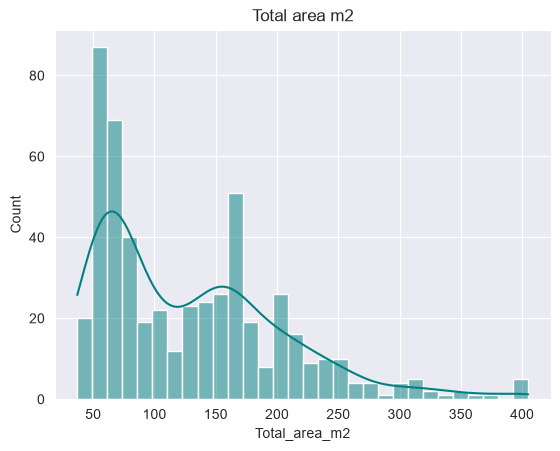

In [338]:
sns.histplot(data=datos,x='Total_area_m2', color='teal', kde=True, bins=30)
plt.title('Total area m2')
plt.show()

In [339]:
datos['Total_area_m2'].describe()

count    521.000000
mean     129.998081
std       75.723167
min       37.000000
25%       65.000000
50%      117.000000
75%      170.000000
max      405.000000
Name: Total_area_m2, dtype: float64

### Built_area_m2

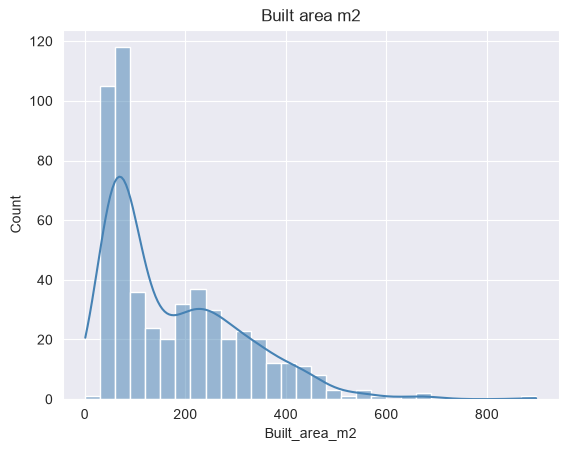

In [340]:
sns.histplot(data=datos,x='Built_area_m2', color='steelblue', kde=True, bins=30)
plt.title('Built area m2')
plt.show()

In [341]:
datos['Built_area_m2'].describe()

count    521.000000
mean     175.884837
std      134.195660
min        1.000000
25%       65.000000
50%      122.000000
75%      262.000000
max      898.000000
Name: Built_area_m2, dtype: float64

In [342]:
irregulares = datos[datos['Built_area_m2'] < 10]
irregulares.head()

,Total_area_m2,Built_area_m2,Rooms,Bathrooms,HalfBathrooms,Parkings,Antiguedad,Colonia,Price,Maintenance_cost,PropertyType,HaveVideo,Latitude,Longitude,cuartiles_total_area_m2
293,68,1,2,1,0,0,20.0,Nueva Atzacoalco,1480000,0,Apartamento,False,19.496496,-99.086499,q3


In [343]:
# Aplicar la asignación condicional usando .loc[filas, columna]
datos.loc[datos['Built_area_m2'] < 10, 'Built_area_m2'] = datos['Total_area_m2']

# (Opcional) Verificar que ya no existan registros menores a 10 m2 en 'Built_area_m2'
# (a menos que 'Total_area_m2' también haya sido menor a 10)
print("Registros restantes con Built_area_m2 < 10:")
print(len(datos[datos['Built_area_m2'] < 10]))


Registros restantes con Built_area_m2 < 10:
0


In [344]:
datos[datos['Built_area_m2'] > 500].describe()

,Total_area_m2,Built_area_m2,Rooms,Bathrooms,HalfBathrooms,Parkings,Antiguedad,Price,Maintenance_cost,Latitude,Longitude
count,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,8.00000,9.000000e+00,9.0,9.000000,9.000000
mean,290.000000,628.222222,5.333333,3.555556,0.333333,2.333333,43.62500,1.410944e+07,0.0,19.490504,-99.128168
std,116.346465,116.093473,2.500000,1.878238,0.500000,1.224745,15.23096,5.464536e+06,0.0,0.015703,0.009654
min,143.000000,530.000000,3.000000,0.000000,0.000000,0.000000,30.00000,7.060000e+06,0.0,19.459540,-99.142156
25%,160.000000,550.000000,4.000000,3.000000,0.000000,2.000000,34.50000,9.950000e+06,0.0,19.487672,-99.133269
50%,357.000000,575.000000,5.000000,3.000000,0.000000,2.000000,36.50000,1.385000e+07,0.0,19.489575,-99.127560
75%,395.000000,674.000000,5.000000,4.000000,1.000000,3.000000,49.25000,1.650000e+07,0.0,19.506000,-99.127400
max,405.000000,898.000000,10.000000,7.000000,1.000000,4.000000,75.00000,2.524500e+07,0.0,19.506472,-99.110452


In [345]:
datos = datos[datos['Built_area_m2'] <= 600]

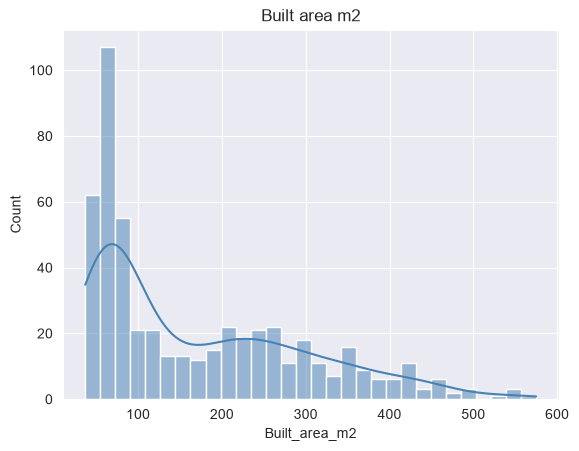

In [346]:
sns.histplot(data=datos,x='Built_area_m2', color='steelblue', kde=True, bins=30)
plt.title('Built area m2')
plt.show()

In [347]:
datos.info()

<class 'pandas.DataFrame'>
Index: 517 entries, 1 to 545
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Total_area_m2            517 non-null    int64   
 1   Built_area_m2            517 non-null    int64   
 2   Rooms                    517 non-null    int64   
 3   Bathrooms                517 non-null    int64   
 4   HalfBathrooms            517 non-null    int64   
 5   Parkings                 517 non-null    int64   
 6   Antiguedad               477 non-null    float64 
 7   Colonia                  517 non-null    str     
 8   Price                    517 non-null    int64   
 9   Maintenance_cost         517 non-null    int64   
 10  PropertyType             517 non-null    str     
 11  HaveVideo                517 non-null    bool    
 12  Latitude                 517 non-null    float64 
 13  Longitude                517 non-null    float64 
 14  cuartiles_total_area_m2  5

### Rooms

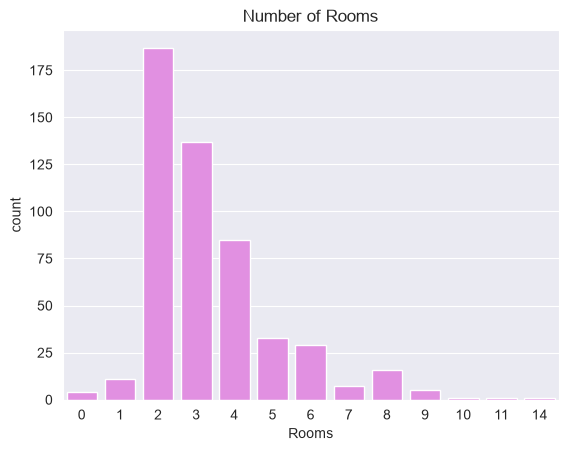

In [348]:
sns.countplot(data=datos, x='Rooms', color='violet')
plt.title('Number of Rooms')
plt.show()

In [349]:
datos = datos[(datos['Rooms'] >= 1) & (datos['Rooms'] <= 9)]

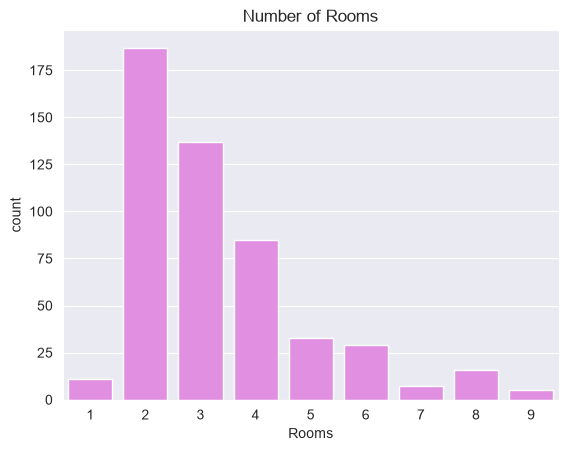

In [350]:
sns.countplot(data=datos, x='Rooms', color='violet')
plt.title('Number of Rooms')
plt.show()

### Bathrooms


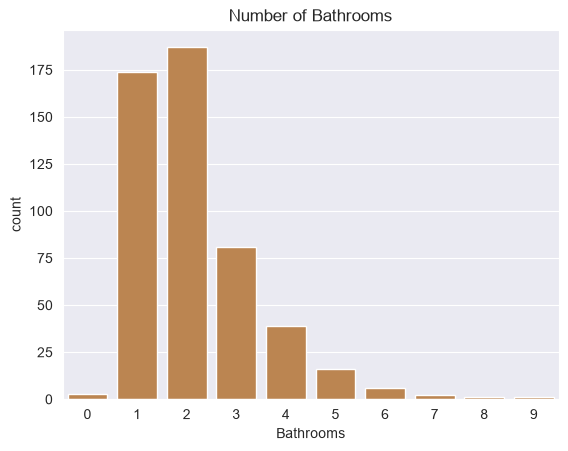

In [351]:
sns.countplot(data=datos, x='Bathrooms', color='peru')
plt.title('Number of Bathrooms')
plt.show()

In [352]:
datos = datos[(datos['Bathrooms'] >= 1)]

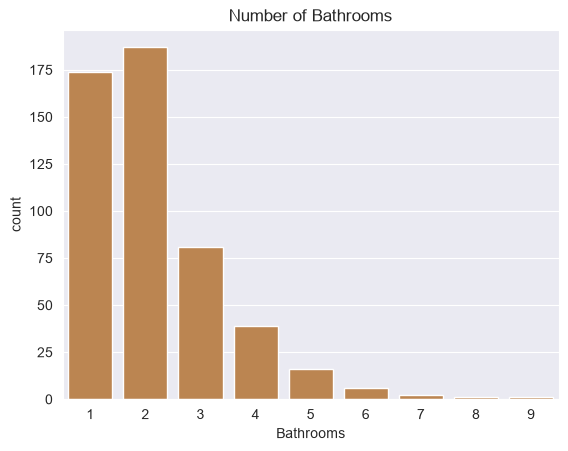

In [353]:
sns.countplot(data=datos, x='Bathrooms', color='peru')
plt.title('Number of Bathrooms')
plt.show()

### Halfbathrooms

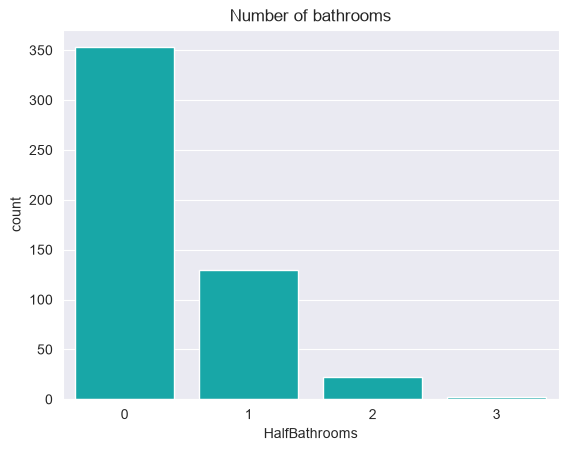

In [354]:
sns.countplot(data=datos, x='HalfBathrooms', color='c')
plt.title('Number of bathrooms')
plt.show()

### Parkings

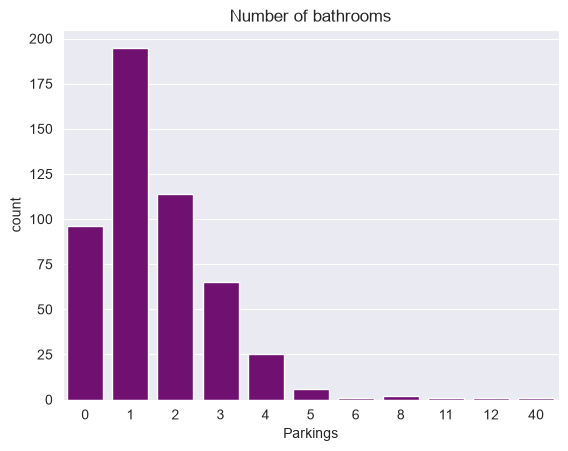

In [ ]:
sns.countplot(data=datos, x='Parkings', color='purple')
plt.title('Parkings')
plt.show()

In [356]:
datos = datos[datos['Parkings'] <= 8]

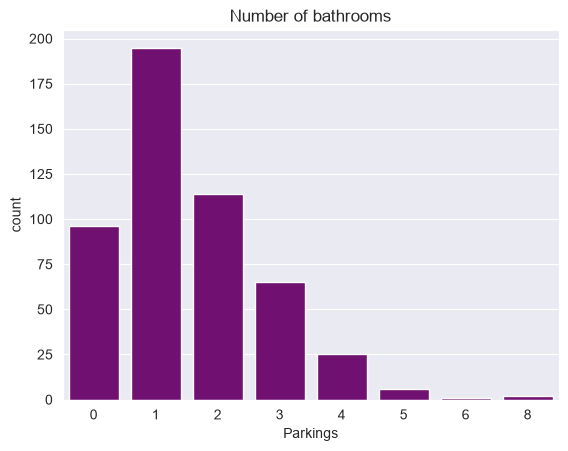

In [ ]:
sns.countplot(data=datos, x='Parkings', color='purple')
plt.title('Parkings')
plt.show()

In [358]:
datos.info()

<class 'pandas.DataFrame'>
Index: 504 entries, 1 to 545
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Total_area_m2            504 non-null    int64   
 1   Built_area_m2            504 non-null    int64   
 2   Rooms                    504 non-null    int64   
 3   Bathrooms                504 non-null    int64   
 4   HalfBathrooms            504 non-null    int64   
 5   Parkings                 504 non-null    int64   
 6   Antiguedad               466 non-null    float64 
 7   Colonia                  504 non-null    str     
 8   Price                    504 non-null    int64   
 9   Maintenance_cost         504 non-null    int64   
 10  PropertyType             504 non-null    str     
 11  HaveVideo                504 non-null    bool    
 12  Latitude                 504 non-null    float64 
 13  Longitude                504 non-null    float64 
 14  cuartiles_total_area_m2  5

<hr />

In order to impute the value correctly, Let's start from the fact that most of the **Colonias** were made in a similar epoc, so, we'll divide the data using the **Colonias** and in the case that the variance of the **Antiguedad** isn't big, we'll impute using the media, otherwise, we'll use the median